# SAT3 TGLF Parameter Scans (Task 1)

This notebook ingests the 43-case SAT3 starter dataset (TGLF SAT2 runs) and reproduces the
parameter-scan plots and findings described in `findings_summary.md`, examining how ion heat
flux $Q_i$ responds to changes in temperature gradient, density gradient, collisionality,
magnetic shear, plasma elongation, and minor radius, with comparisons across hydrogen (H),
deuterium (D), and tritium (T) ion species.

The ingestion and plotting logic mirrors `generate_plots.py` in this same directory (which can
still be run as a standalone script); this notebook runs the same code cell-by-cell so the
analysis and resulting plots render inline. `generate_plots.py` and `findings_summary.md` are
left untouched.

## 1. Dataset Architecture
The SAT3 starter dataset consists of 43 simulation runs under `data/<case>/tglf_sat2/`. Each case has identical data structures:
- `input.tglf.gen`: 180 total plasma and numerical settings.
- `out.tglf.gbflux`: 8 values ($4 \times NS$ for $NS=2$) representing Particle Flux $\Gamma$, Heat Flux $Q$, Exchange (skipped), and Toroidal Momentum Flux $\Pi$.

### Standard Reference Baseline (`a`)
- Temperature gradients: `RLTS_1 = RLTS_2 = 3.0`
- Density gradients: `RLNS_1 = RLNS_2 = 1.0`
- Temperature ratio: `TAUS_2 = 1.0` ($T_i = T_e$)
- Collision frequency: `XNUE = 0.1`
- Geometry: `RMIN_LOC = 0.5`, `DRMAJDX_LOC = 0.0`, `KAPPA_LOC = 1.0` (circular)
- Magnetic safety factor: `Q_LOC = 2.0`, `Q_PRIME_LOC = 16.0`

In [1]:
# Step 1: imports and path setup
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def find_repo_root(start=None):
    # Walk upward from `start` (default: cwd) until a directory containing both
    # `src/` and `notebooks/` is found. Falls back to `start` if no such ancestor
    # exists, so the notebook works whether Jupyter's cwd is the repo root or the
    # notebook's own directory.
    p = Path(start or Path.cwd()).resolve()
    for _ in range(6):
        if (p / "src").is_dir() and (p / "notebooks").is_dir():
            return p
        if p.parent == p:
            break
        p = p.parent
    return Path(start or Path.cwd()).resolve()


REPO_ROOT = find_repo_root()
sys.path.insert(0, str(REPO_ROOT / "src"))

# parse_sat3.py (used by generate_plots.py) was folded into src/tglf_parser.py;
# both expose the same load_all_cases(data_dir) function.
from tglf_parser import load_all_cases

print(f"Repo root resolved to: {REPO_ROOT}")

Repo root resolved to: /Users/Aryan/Desktop/UCSD Coursework/Fall 2026/DSC 180A/dsc180a-project-1


In [2]:
# Step 2: locate and load the 43 SAT3 cases.
# Checked in order: an explicit SAT3_DATA_DIR env override, the location named in
# data/README.md (data/Task1_TGLF_SAT3_dataset/SAT3_dataset/data), then the
# `SAT3_dataset/data` convention used directly by generate_plots.py (relative to the
# repo root, then relative to the current working directory).
_candidates = [
    os.environ.get("SAT3_DATA_DIR"),
    REPO_ROOT / "data" / "Task1_TGLF_SAT3_dataset" / "SAT3_dataset" / "data",
    REPO_ROOT / "SAT3_dataset" / "data",
    Path("SAT3_dataset/data"),
]

dataset_path = next((Path(c) for c in _candidates if c and Path(c).is_dir()), None)
if dataset_path is None:
    raise FileNotFoundError(
        "Could not find the SAT3 dataset. Set the SAT3_DATA_DIR environment variable "
        "or place the extracted dataset at data/Task1_TGLF_SAT3_dataset/SAT3_dataset/ "
        "per data/README.md."
    )

print(f"Loading SAT3 cases from: {dataset_path}")
df, errors = load_all_cases(dataset_path)
df["letter"] = df["case"].apply(lambda x: x.split("_")[0])

print(f"Parsed {len(df)} cases with {len(errors)} errors.")
df.head()

Loading SAT3 cases from: /Users/Aryan/Desktop/UCSD Coursework/Fall 2026/DSC 180A/dsc180a-project-1/data/Task1_TGLF_SAT3_dataset/SAT3_dataset/data
Parsed 43 cases with 0 errors.


,case,NS,XNUE,RMIN_LOC,DRMAJDX_LOC,KAPPA_LOC,Q_LOC,Q_PRIME_LOC,MASS_1,ZS_1,...,Gamma_e,Q_e,Pi_e,Gamma_2,Q_2,Pi_2,Gamma_i,Q_i,Pi_i,letter
0,a_D,2,0.1,0.5,0.0,1.0,2.0,16.0,0.000272,-1,...,1.84440,15.2580,10.79100,1.84440,43.1010,-10.54800,1.84440,43.1010,-10.54800,a
1,a_H,2,0.1,0.5,0.0,1.0,2.0,16.0,0.000272,-1,...,1.06430,12.6180,8.47800,1.06430,34.6730,-8.26180,1.06430,34.6730,-8.26180,a
2,a_T,2,0.1,0.5,0.0,1.0,2.0,16.0,0.000272,-1,...,2.40070,16.7390,12.32300,2.40070,48.7330,-12.06500,2.40070,48.7330,-12.06500,a
3,b_D,2,0.1,0.5,0.0,1.0,2.0,16.0,0.000272,-1,...,0.74508,2.2156,0.98869,0.74508,4.7995,-0.97831,0.74508,4.7995,-0.97831,b
4,b_H,2,0.1,0.5,0.0,1.0,2.0,16.0,0.000272,-1,...,0.59587,1.9686,0.87135,0.59587,4.3800,-0.86103,0.59587,4.3800,-0.86103,b


## 2. Parameter Variation Map
- **Triplets (24 runs: H, D, T)**:
  - `a`: Reference baseline
  - `b, c, d`: Ion & electron temperature gradient scan (`RLTS` = 1.5, 2.25, 3.5)
  - `e, f`: Density gradient scan (`RLNS` = 2.0, 3.0)
  - `j`: Low electron collision frequency (`XNUE = 0.01`)
  - `x`: High density gradient (`RLNS = 3.0`) + low collisions (`XNUE = 0.01`)
- **Doublet (2 runs: H, T)**:
  - `y`: High density gradient (`RLNS = 3.0`) + intermediate collisions (`XNUE = 0.05`)
- **Deuterium-Only Scans (17 runs: D only)**:
  - `g, h, i`: Magnetic shear (`Q_PRIME_LOC` = 4.0, 8.0, 24.0)
  - `k`: High collision frequency (`XNUE = 1.0`)
  - `l, m`: Temperature ratio (`TAUS_2` = 0.5, 1.5)
  - `n, o`: Safety factor (`Q_LOC` = 1.5, 2.5)
  - `p, q, r`: Plasma elongation (`KAPPA_LOC` = 1.25, 1.5, 2.0)
  - `s, t, u`: Shafranov shift derivative (`DRMAJDX_LOC` = -0.125, -0.25, -0.5)
  - `v, w`: Minor radius radial location (`RMIN_LOC` = 0.75, 0.25)
  - `z`: High density gradient (`RLNS = 3.0`) + high collisions (`XNUE = 1.0`)

In [3]:
# plot_scan: same plotting logic as generate_plots.py. Each scan plots the lines where
# only the named drive (x_col) is changed (the "pure" letters, resolved per species), while
# points from other cases that share an ion species but changed additional inputs are shown
# faded in the background for context. Figures are saved to plots/ (same filenames as
# generate_plots.py) and also rendered inline via plt.show().
PLOTS_DIR = REPO_ROOT / "notebooks" / "aryan" / "task1" / "plots"
PLOTS_DIR.mkdir(exist_ok=True, parents=True)

SPECIES_COLORS = {"H": "#1f77b4", "D": "#2ca02c", "T": "#d62728"}


def plot_scan(
    df,
    x_col,
    pure_letters,
    title,
    xlabel,
    ylabel,
    output_path,
    is_x_log=False,
    species_list=["H", "D", "T"],
):
    fig, ax = plt.subplots(figsize=(6, 4.5))

    df_pure = df[df["letter"].isin(pure_letters)]
    df_other = df[~df["case"].isin(df_pure["case"])]

    for spec in species_list:
        sub_other = df_other[df_other["species_type_2"] == spec]
        color = SPECIES_COLORS.get(spec, "#7f7f7f")
        ax.scatter(
            sub_other[x_col],
            sub_other["Q_i"],
            color=color,
            alpha=0.25,
            s=35,
            edgecolors="none",
        )

    for spec in species_list:
        sub_pure = df_pure[df_pure["species_type_2"] == spec].sort_values(x_col)
        color = SPECIES_COLORS.get(spec, "#7f7f7f")
        if not sub_pure.empty:
            ax.plot(
                sub_pure[x_col],
                sub_pure["Q_i"],
                color=color,
                marker="o",
                markersize=6,
                linewidth=1.8,
                label=spec,
            )

    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel(xlabel, fontsize=10.5)
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.grid(True, linestyle="-", alpha=0.3, color="#d3d3d3")

    if is_x_log:
        ax.set_xscale("log")

    legend_elements = []
    for spec in species_list:
        legend_elements.append(
            Line2D(
                [0],
                [0],
                color=SPECIES_COLORS.get(spec, "#7f7f7f"),
                marker="o",
                markersize=6,
                linewidth=1.8,
                label=spec,
            )
        )
    legend_elements.append(
        Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor="#b0b0b0",
            markersize=6,
            alpha=0.5,
            label="other inputs\nalso changed",
        )
    )

    legend_title = (
        "Ion species\n(lines: only drive changed)"
        if len(species_list) > 1
        else "Deuterium scan\n(lines: only drive changed)"
    )
    ax.legend(
        handles=legend_elements,
        title=legend_title,
        loc="center left",
        bbox_to_anchor=(1.04, 0.5),
        frameon=True,
        fontsize=9,
        title_fontsize=9.5,
    )

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

### Temperature gradient scan (`RLTS_2`)
Introduced in Section 2 as the `b, c, d` triplet scan (`RLTS` = 1.5, 2.25, 3.5) around the
baseline `a`. `findings_summary.md` does not include a written trend discussion for this
scan, so the plot below is generated for completeness alongside the others.

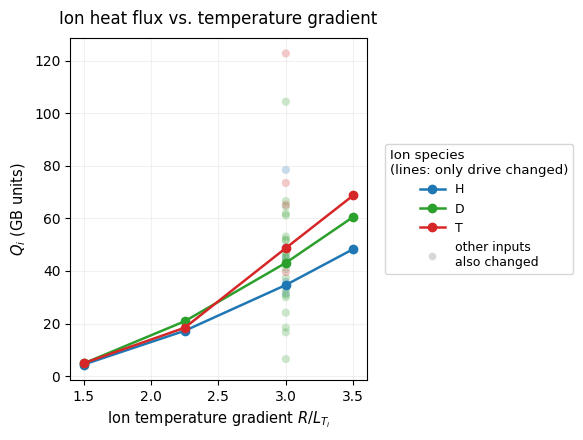

In [4]:
plot_scan(
    df=df,
    x_col="RLTS_2",
    pure_letters=["b", "c", "a", "d"],
    title="Ion heat flux vs. temperature gradient",
    xlabel="Ion temperature gradient $R/L_{T_i}$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_temperature_gradient.png",
    is_x_log=False,
    species_list=["H", "D", "T"],
)

### Density gradient scan (`RLNS_2`)
Introduced in Section 2 as the `e, f` triplet scan (`RLNS` = 2.0, 3.0) around the baseline `a`.
As with the temperature-gradient scan, `findings_summary.md` does not include a written trend
discussion for this scan on its own (it is revisited together with collisionality in Sections 3B
and 4 below), so the plot is shown here for completeness.

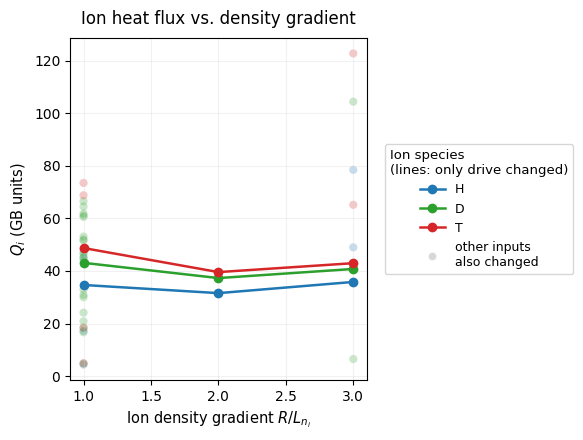

In [5]:
plot_scan(
    df=df,
    x_col="RLNS_2",
    pure_letters=["a", "e", "f"],
    title="Ion heat flux vs. density gradient",
    xlabel="Ion density gradient $R/L_{n_i}$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_density_gradient.png",
    is_x_log=False,
    species_list=["H", "D", "T"],
)

## 3. Deuterium Focused Scans

### A. Magnetic Shear (`Q_PRIME_LOC`)
- `g_D` (4.0): $Q_i = 18.47$, $Q_e = 7.04$, $\Pi_i = -2.26$
- `h_D` (8.0): $Q_i = 30.01$, $Q_e = 10.97$, $\Pi_i = -4.29$
- `a_D` (16.0): $Q_i = 43.10$, $Q_e = 15.26$, $\Pi_i = -10.55$
- `i_D` (24.0): $Q_i = 51.56$, $Q_e = 17.41$, $\Pi_i = -18.14$
- **Trend**: Both heat and momentum transport increase monotonically with higher magnetic shear.

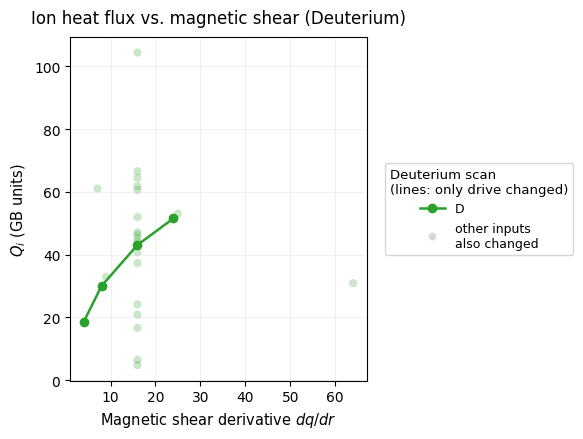

In [6]:
plot_scan(
    df=df,
    x_col="Q_PRIME_LOC",
    pure_letters=["g", "h", "a", "i"],
    title="Ion heat flux vs. magnetic shear (Deuterium)",
    xlabel="Magnetic shear derivative $dq/dr$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_magnetic_shear_deuterium.png",
    is_x_log=False,
    species_list=["D"],
)

### B. Collision Frequency (`XNUE`)
- Baseline drive (`RLNS = 1.0`):
  - `j_D` (0.01): $Q_i = 61.86$, $Q_e = 19.94$, $\Gamma_e = -0.093$ (particle pinch)
  - `a_D` (0.10): $Q_i = 43.10$, $Q_e = 15.26$, $\Gamma_e = 1.844$
  - `k_D` (1.00): $Q_i = 24.14$, $Q_e = 8.95$, $\Gamma_e = 1.681$
- Steep density drive (`RLNS = 3.0`):
  - `x_D` (0.01): $Q_i = 104.43$, $Q_e = 105.32$, $\Gamma_e = 37.79$
  - `f_D` (0.10): $Q_i = 40.77$, $Q_e = 43.74$, $\Gamma_e = 15.08$
  - `z_D` (1.00): $Q_i = 6.49$, $Q_e = 7.63$, $\Gamma_e = 2.45$
- **Trend**: Collisional detrapping strongly stabilizes trapped electron modes (TEM), reducing fluxes by up to 16x at high density gradients.

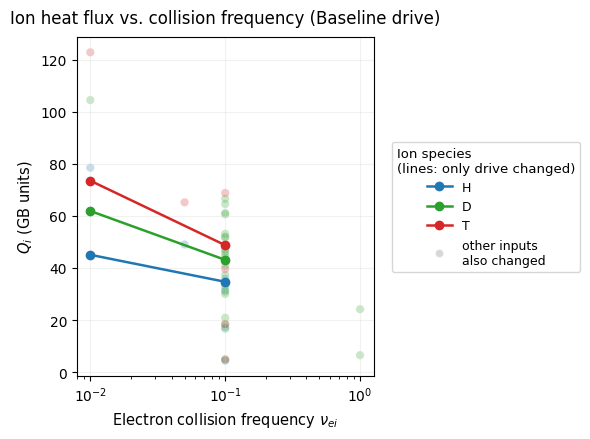

In [7]:
plot_scan(
    df=df,
    x_col="XNUE",
    pure_letters=["j", "a"],
    title="Ion heat flux vs. collision frequency (Baseline drive)",
    xlabel="Electron collision frequency $\\nu_{ei}$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_collision_frequency_baseline.png",
    is_x_log=True,
    species_list=["H", "D", "T"],
)

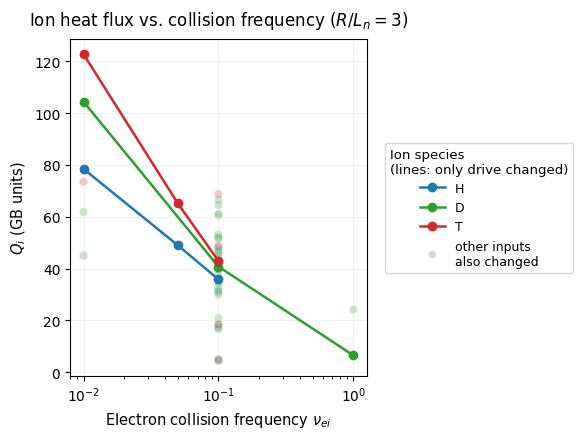

In [8]:
plot_scan(
    df=df,
    x_col="XNUE",
    pure_letters=["x", "y", "f", "z"],
    title="Ion heat flux vs. collision frequency ($R/L_n = 3$)",
    xlabel="Electron collision frequency $\\nu_{ei}$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_collision_frequency_steep_density.png",
    is_x_log=True,
    species_list=["H", "D", "T"],
)

### C. Plasma Elongation (`KAPPA_LOC`)
- `a_D` (1.00): $Q_i = 43.10$, $Q_e = 15.26$, $\Gamma_e = 1.84$
- `p_D` (1.25): $Q_i = 47.12$, $Q_e = 17.01$, $\Gamma_e = 2.07$
- `q_D` (1.50): $Q_i = 52.00$, $Q_e = 19.37$, $\Gamma_e = 2.34$
- `r_D` (2.00): $Q_i = 66.60$, $Q_e = 25.56$, $\Gamma_e = 3.21$
- **Trend**: In normalized gyro-Bohm units, higher elongation increases transport uniformly across all channels.

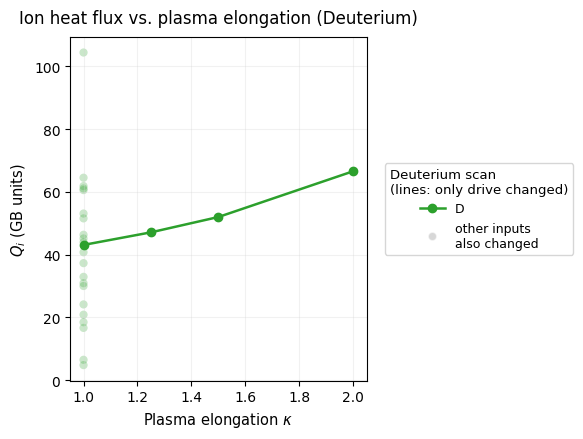

In [9]:
plot_scan(
    df=df,
    x_col="KAPPA_LOC",
    pure_letters=["a", "p", "q", "r"],
    title="Ion heat flux vs. plasma elongation (Deuterium)",
    xlabel="Plasma elongation $\\kappa$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_elongation_deuterium.png",
    is_x_log=False,
    species_list=["D"],
)

### D. Minor Radius (`RMIN_LOC`)
The dataset also includes a deuterium-only scan of the radial location (`RMIN_LOC` = 0.25,
0.5, 0.75; letters `w`, `a`, `v`; see Section 2). `findings_summary.md` does not report a
written trend for this scan, so the plot below is shown for completeness alongside the other
deuterium-focused parameter scans above.

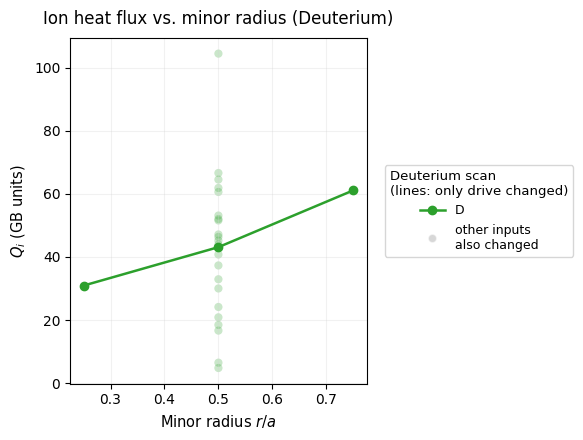

In [10]:
plot_scan(
    df=df,
    x_col="RMIN_LOC",
    pure_letters=["w", "a", "v"],
    title="Ion heat flux vs. minor radius (Deuterium)",
    xlabel="Minor radius $r/a$",
    ylabel="$Q_i$ (GB units)",
    output_path=PLOTS_DIR / "qi_vs_minor_radius_deuterium.png",
    is_x_log=False,
    species_list=["D"],
)

## 4. Collision Frequency Isotope Comparison (H, D, T)
The two collision-frequency plots above (Section 3B) already overlay the H, D, and T traces;
the numeric breakdown behind those lines is reproduced here from `findings_summary.md`.

### Baseline Density (`RLNS = 1.0`)
- `XNUE = 0.01` (`j`):
  - H: $Q_i = 45.04$, $Q_e = 14.88$, $\Gamma_e = -0.391$
  - D: $Q_i = 61.86$, $Q_e = 19.94$, $\Gamma_e = -0.093$
  - T: $Q_i = 73.49$, $Q_e = 23.60$, $\Gamma_e = +0.214$
- `XNUE = 0.10` (`a`):
  - H: $Q_i = 34.67$, $Q_e = 12.62$, $\Gamma_e = +1.064$
  - D: $Q_i = 43.10$, $Q_e = 15.26$, $\Gamma_e = +1.844$
  - T: $Q_i = 48.73$, $Q_e = 16.74$, $\Gamma_e = +2.401$

### Steep Density (`RLNS = 3.0`)
- `XNUE = 0.01` (`x`): H: $Q_i = 78.48$, D: $Q_i = 104.43$, T: $Q_i = 122.78$ ($Q_e/Q_i \approx 1.01$)
- `XNUE = 0.05` (`y`): H: $Q_i = 48.99$, T: $Q_i = 65.18$ ($Q_e/Q_i \approx 1.05$)
- `XNUE = 0.10` (`f`): H: $Q_i = 35.83$, D: $Q_i = 40.77$, T: $Q_i = 42.97$ ($Q_e/Q_i \approx 1.08$)
- `XNUE = 1.00` (`z`): D: $Q_i = 6.49$ ($Q_e/Q_i = 1.18$)